## Sequential Algorithm for Open-Pit Mine Scheduling Problem (zuck_small, HiGHS only)

Same notebook as `zuck_small.ipynb`, solved only with the open-source solver HiGHS. The changes, marked `# added` in the code, are:

1. Solver fixed to HiGHS (`solver_name = "HIGHS"`).
2. HiGHS log of every subproblem written to `zuck_small_highs_sdcpit.log` and printed in the notebook (`solver_log`).
3. Output files with the suffix `_highs`, so that the Gurobi results in the same folder are not overwritten.

### Installing packages

In [1]:
!pip install -q pandas==3.0.2 numpy==2.4.4 mip==2.0.0 highspy==1.15.1 highsbox==1.15.1 matplotlib==3.10.8 plotly==6.6.0

### Importing packages

In [2]:
import os, time, pandas as pd, plotly.express as px, matplotlib.pyplot as plt, numpy as np
from mip import *

### Solver log helper

In [3]:
# added: solver log through Python-MIP and storage of results for the final comparison
# CBC and HiGHS write their log to the C standard output of the process, which Jupyter does not show.
# The C standard output is redirected to a log file while the solver runs, and the log is then printed
# in the notebook. The models themselves are not changed.
import contextlib, ctypes, sys


def _c_flush():
    # Flush the C standard output buffer (the solvers write through the C runtime)
    try:
        lib = ctypes.CDLL("ucrtbase") if sys.platform == "win32" else ctypes.CDLL(None)
        lib.fflush(None)
    except Exception:
        pass


@contextlib.contextmanager
def solver_log(log_file, append=False, show=True):
    # Write the solver log of the enclosed optimize() call to log_file and print it in the notebook
    sys.stdout.flush()
    _c_flush()
    start = os.path.getsize(log_file) if append and os.path.exists(log_file) else 0
    saved = os.dup(1)
    with open(log_file, "ab" if append else "wb") as f:
        os.dup2(f.fileno(), 1)
        try:
            yield
        finally:
            _c_flush()
            os.dup2(saved, 1)
            os.close(saved)
    if show:
        with open(log_file, "rb") as f:
            f.seek(start)
            text = f.read().decode("utf-8", errors="replace")
        print(text if text.strip() else f"(no solver output captured in {log_file})")


### Loading block model file

In [4]:
# Load block model 
cols = ["id", "x", "y", "z", "cost", "value", "rock_tonnes", "ore_tonnes"]

# Read the block model (space-separated format)
blocks = pd.read_csv("zuck_small.blocks", sep=r"\s+", header=None, names=cols, engine="python")

# Calculating block value 
blocks['blockvalue'] = blocks['value'] - blocks['cost']

# Add a column to store the extraction period (initially empty)
blocks["period"] = pd.NA

print(f"Loaded {len(blocks):,} blocks")

Loaded 9,400 blocks


### Loading block precedences file

In [5]:
# Load precedence relations (Precedence file format: block_id  n_prec  prec1  prec2  ... )
precedence = {}
with open("zuck_small.prec") as f:
    for line in f:
        parts = line.strip().split()
        block_id = int(parts[0])
        n_prec = int(parts[1])
        precedence[block_id] = [int(parts[k]) for k in range(2, 2+n_prec)]

print(f"Loaded {sum(len(precs) for precs in precedence.values()):,} precedences")

Loaded 145,640 precedences


### Sequential Algorithm for Open-Pit Mine Scheduling

In [6]:
# Parameters 
max_period = 20     # Maximum number of scheduling periods
MC = 60_000_000     # Maximum Mine Capacity (tons)
PC = 20_000_000     # Maximum Process Capacity (tons), MineLib zuck_small.cpit
alpha = 0.10        # Discount rate for Net Present Value (NPV)

# Sequential Optimization 
code_start = time.time()
period_profit = []   # Store discounted values per period
extracted = set()    # Keep track of already extracted blocks

solver_name = "HIGHS"  # added: HiGHS only
print(f"Using {solver_name} solver")
print("Starting optimization")

# Loop over scheduling periods
for t in range(max_period):

    # Available blocks = those not extracted yet
    B = list(blocks.index[~blocks["id"].isin(extracted)])
    if not B:
        break  # Stop if no available blocks remain

    # Extract data for available blocks
    ids = blocks.loc[B, "id"].tolist()
    v = blocks.loc[B, "blockvalue"].tolist()
    rock = blocks.loc[B, "rock_tonnes"].tolist()
    ore = blocks.loc[B, "ore_tonnes"].tolist()

    model = Model(sense=MAXIMIZE, solver_name=solver_name)
    model.max_seconds = 600  # 10 minutes

    # Decision variables: x[b] = 1 if block b is extracted in this period
    x = [model.add_var(var_type=BINARY) for _ in B]

    # Objective: maximize undiscounted profit in this period
    model.objective = xsum(x[b] * v[b] for b in range(len(B)))

    # Precedence constraints: a block can only be extracted if its predecessors are extracted
    id_to_var = {ids[b]: b for b in range(len(B))}
    for bid in ids:
        if bid in precedence:
            for prec in precedence[bid]:
                if prec in extracted:
                    continue  # Already extracted in earlier period
                elif prec in id_to_var:
                    model += x[id_to_var[bid]] <= x[id_to_var[prec]]
                else:
                    # Predecessor not extracted yet → force this block = 0
                    model += x[id_to_var[bid]] == 0

    # Capacity constraint (only processing blocks where destination=1)
    model += xsum(ore[b] * x[b] for b in range(len(B))) <= PC
    model += xsum(rock[b] * x[b] for b in range(len(B))) <= MC

    # Solve optimization 
    opt_start = time.time()
    with solver_log("zuck_small_highs_sdcpit.log", append=t > 0, show=False):  # added: HiGHS log (all periods in the same file)
        model.optimize()
    opt_time = time.time() - opt_start

    # Check solution status
    if model.status in (OptimizationStatus.OPTIMAL, OptimizationStatus.FEASIBLE) and model.objective_value > 0:
        undiscounted_value = model.objective_value
        discounted_value = undiscounted_value / ((1 + alpha) ** t)
        period_profit.append(discounted_value)

        # Update extracted blocks
        files_start = time.time()
        selected = []
        for b, var in enumerate(x):
            if var.x > 0.5:  # If block is selected
                bid = ids[b]
                extracted.add(bid)
                blocks.loc[blocks["id"] == bid, "period"] = t
                selected.append(bid)
        files_time = time.time() - files_start

        # Print summary for this period
        print(f"Period: {t} | "
              f"Undiscounted: {undiscounted_value:,.0f} | " f"Discounted: {discounted_value:,.0f} | " f"Blocks: {len(selected)} | "
              f"Opt Time (min): {opt_time/60:.2f} | " f"Files Time (min): {files_time/60:.2f}")
    else:
        break

    # Clear model (free memory before next period)
    model.clear()

# Final Results 
npv = sum(period_profit)  # Net Present Value
print(f"\nNPV: {npv:,.0f}")
print(f"Total blocks extracted: {len(extracted)}")
print(f"Code Time: {(time.time()-code_start)/60:.2f} minutes")

# Save solution 
blocks.to_csv("zuck_small_solution_highs.csv", index=False)

Using HIGHS solver
Starting optimization


HiGHS C API not accessible via 'C:\\Users\\dougl\\miniconda3\\Lib\\site-packages\\highspy\\_core.cp314-win_amd64.pyd' (typical on Windows with highspy). Falling back to highsbox.


Period: 0 | Undiscounted: 98,287,180 | Discounted: 98,287,180 | Blocks: 418 | Opt Time (min): 0.57 | Files Time (min): 0.00
Period: 1 | Undiscounted: 101,501,851 | Discounted: 92,274,410 | Blocks: 377 | Opt Time (min): 2.11 | Files Time (min): 0.00
Period: 2 | Undiscounted: 113,260,247 | Discounted: 93,603,510 | Blocks: 370 | Opt Time (min): 0.61 | Files Time (min): 0.00
Period: 3 | Undiscounted: 121,606,045 | Discounted: 91,364,421 | Blocks: 426 | Opt Time (min): 0.26 | Files Time (min): 0.00
Period: 4 | Undiscounted: 117,710,213 | Discounted: 80,397,660 | Blocks: 400 | Opt Time (min): 0.45 | Files Time (min): 0.00
Period: 5 | Undiscounted: 117,156,058 | Discounted: 72,744,694 | Blocks: 452 | Opt Time (min): 1.03 | Files Time (min): 0.00
Period: 6 | Undiscounted: 116,420,348 | Discounted: 65,716,252 | Blocks: 496 | Opt Time (min): 0.33 | Files Time (min): 0.00
Period: 7 | Undiscounted: 109,185,388 | Discounted: 56,029,368 | Blocks: 490 | Opt Time (min): 0.32 | Files Time (min): 0.00
P

### Mine Scheduling 3D Plot

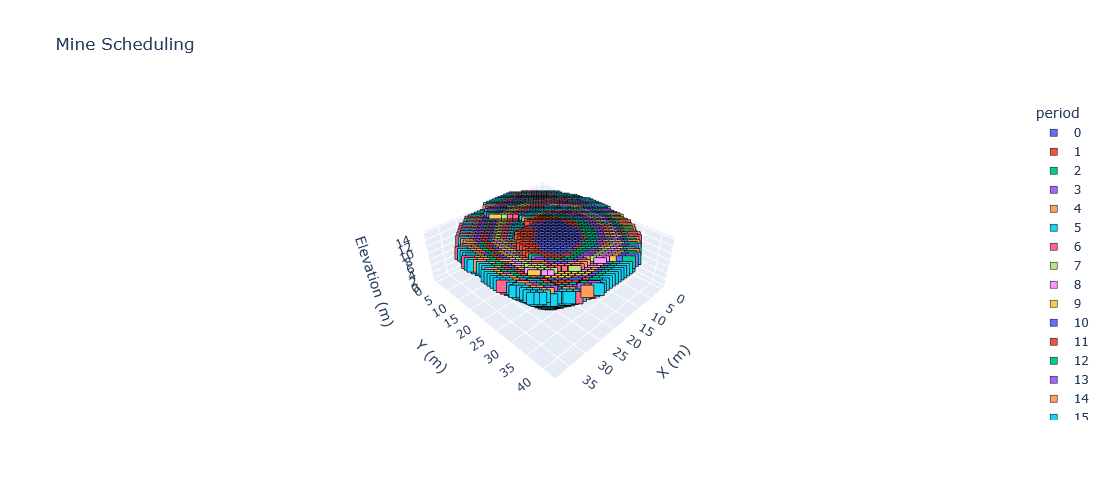

In [7]:
# Block dimensions
dx, dy, dz = 1, 1, 1

# Filter extracted blocks and prepare data
d = blocks.loc[blocks.period.notna()].copy()
d["period"] = d["period"].astype(int)
d[["x","y","z"]] *= [dx, dy, dz]
d["period"] -= d["period"].min()
d["period"] = d["period"].astype(str)

# Axis scaling for correct proportions
r = d[["x","y","z"]].max() - d[["x","y","z"]].min()
s = r.max()

# 3D categorical scatter with Plotly default colors
fig = px.scatter_3d(d, x="x", y="y", z="z", color="period", color_discrete_sequence=px.colors.qualitative.Plotly,
    category_orders={"period": sorted(d["period"], key=int)}, labels={"color": "Periods"}, 
    title="Mine Scheduling", width=900, height=500).update_traces(marker=dict(symbol="square", size=7, 
    line=dict(width=0.5, color="black"))).update_layout(scene=dict(xaxis_title="X (m)", yaxis_title="Y (m)", 
    zaxis_title="Elevation (m)", aspectmode="manual", aspectratio=dict(x=r.x/s, y=r.y/s, z=r.z/s)))
fig.show()

In [8]:
# Salve 3D Plot 
fig.write_html("zuck_small_plot_highs.html", full_html=True, include_plotlyjs="cdn",
    config={"responsive": True}, default_width="100vw", default_height="100vh")

### Capacity & Grade Chart

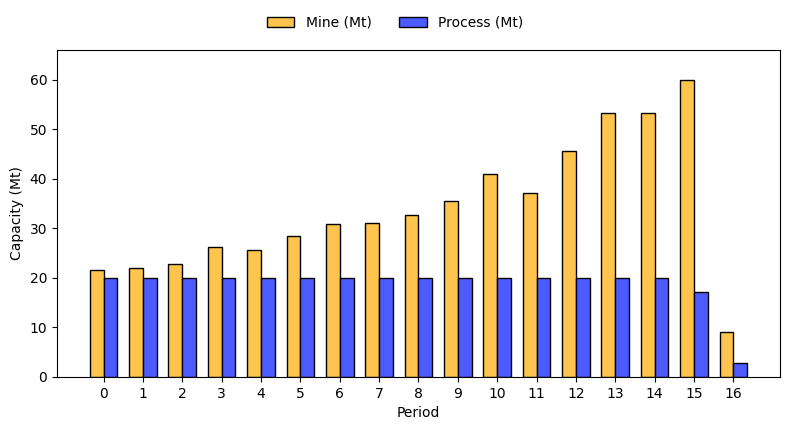

In [9]:
# Consider only extracted blocks
df = blocks.dropna(subset=["period"]).copy()

# Aggregate by period
summary = (df.groupby("period", as_index=False).agg(ton_mine=("rock_tonnes", "sum"), ton_plant=("ore_tonnes", "sum"), ))

# Plot
x = np.arange(len(summary))
w = 0.35
fig, ax1 = plt.subplots(figsize=(8, 4))

# Bars: Mine vs Process capacity (Mt)
ax1.bar(x - w/2, summary["ton_mine"] / 1e6, w, label="Mine (Mt)", color="#FFC44D", edgecolor="black")
ax1.bar(x + w/2, summary["ton_plant"] / 1e6, w, label="Process (Mt)", color="#4C5BFF", edgecolor="black")

ax1.set_xlabel("Period")
ax1.set_ylabel("Capacity (Mt)")
ax1.set_xticks(x)
ax1.set_xticklabels(summary["period"].astype(int))

# Y-axis from zero to slightly above max
ax1.set_ylim(0, 1.1 * max(summary["ton_mine"].max(), summary["ton_plant"].max()) / 1e6)

# Visual hierarchy
ax1.patch.set_visible(False)

# Legend
fig.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)

plt.tight_layout()
plt.show()

In [10]:
# Salve plot
fig.savefig("zuck_small_results_highs.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()